# TP2: Transformer-based Sequence Model for APT Attack Detection

## Master Project: Early Detection of Multi-Stage APT Attacks using the Cyber Kill Chain

### Overview
This notebook implements a Transformer model that operates on autoencoder latent vectors to model APT attack evolution through the Cyber Kill Chain (CKC) stages.

### Model Options:
- **Option A**: Multi-class CKC stage prediction (7 classes)
- **Option B**: Binary early-warning (is next stage S6 or S7?)
- **Option C**: Next latent vector prediction (sequence forecasting)

### Input Data:
- 64-dimensional latent vectors from TP1 autoencoder
- Events grouped by `agent_id`, sorted by `timestamp`
- Sliding windows of configurable length

### Architecture:
- Input Projection (latent_dim → d_model)
- Positional Encoding for temporal awareness
- Multi-head Self-Attention layers
- Task-specific output heads

## Part 1: Imports and Setup

In [16]:
# ============================================================================
# IMPORTS AND SETUP
# ============================================================================

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from collections import defaultdict
from typing import Tuple, List, Dict, Optional, Union
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn.utils.rnn import pad_sequence

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    mean_squared_error, mean_absolute_error
)
from sklearn.preprocessing import LabelEncoder

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.7.1+cpu
Using device: cpu


## Part 2: Configuration

Define all hyperparameters and configuration settings in one place for easy experimentation.

In [31]:
# ============================================================================
# CONFIGURATION CLASS
# ============================================================================

class TransformerConfig:
    """
    Configuration class for Transformer model and training.
    Modify these parameters to experiment with different settings.
    """
    
    # ---------------------- Data Paths ----------------------
    # Path to autoencoder outputs (latent vectors)
    AUTOENCODER_OUTPUT_DIR = r"G:\pfe\Linux-APT-Dataset-2024\autoencoder_outputs"
    LATENT_VECTORS_PATH = os.path.join(AUTOENCODER_OUTPUT_DIR, "latent_vectors.npy")
    CKC_LABELS_PATH = os.path.join(AUTOENCODER_OUTPUT_DIR, "labels_ckc.npy")
    MALICIOUS_LABELS_PATH = os.path.join(AUTOENCODER_OUTPUT_DIR, "labels_malicious.npy")
    
    # Original data for agent_id and timestamps
    ORIGINAL_DATA_PATH = "../combined_dataset_final.xlsx"
    
    # Output directory for this model
    OUTPUT_DIR = "transformer_outputs"
    
    # ---------------------- Model Architecture ----------------------
    INPUT_DIM = 64           # Latent vector dimension from autoencoder
    D_MODEL = 128            # Transformer internal dimension
    N_HEADS = 8              # Number of attention heads
    N_ENCODER_LAYERS = 4     # Number of Transformer encoder layers
    DIM_FEEDFORWARD = 512    # Feedforward network dimension
    DROPOUT = 0.1            # Dropout rate
    
    # ---------------------- Sequence Parameters ----------------------
    SEQ_LENGTH = 4           # Sequence length (number of events) - short for quick attack detection
    STRIDE = 1               # Sliding window stride - smaller for more sequences
    
    # ---------------------- Task Configuration ----------------------
    # Options: 'next_step_prediction', 'ckc_classification', 'early_warning', 'next_latent'
    # next_step_prediction: Given sequence, predict NEXT event's CKC stage (0=benign, 1-7=attack stages)
    TASK = 'next_step_prediction'
    
    # CKC Classification: 8 classes (0=Benign/Normal Traffic, 1-7=CKC stages)
    NUM_CKC_CLASSES = 8
    
    # Early Warning: Binary (0=Safe, 1=Danger: S6 or S7)
    EARLY_WARNING_STAGES = [6, 7]  # Stages that indicate danger
    
    # ---------------------- Training Parameters ----------------------
    BATCH_SIZE = 32
    LEARNING_RATE = 1e-4
    WEIGHT_DECAY = 1e-5
    NUM_EPOCHS = 100
    PATIENCE = 15            # Early stopping patience
    
    # ---------------------- Data Split ----------------------
    TRAIN_RATIO = 0.7
    VAL_RATIO = 0.15
    TEST_RATIO = 0.15
    
    # ---------------------- Positional Encoding ----------------------
    # Options: 'sinusoidal', 'learnable'
    POSITIONAL_ENCODING = 'sinusoidal'
    MAX_SEQ_LENGTH = 500     # Maximum sequence length for positional encoding
    
    # ---------------------- Class Weights ----------------------
    USE_CLASS_WEIGHTS = True  # Use class weights for imbalanced data
    
    def __init__(self, **kwargs):
        """Allow overriding default values"""
        for key, value in kwargs.items():
            if hasattr(self, key):
                setattr(self, key, value)
            else:
                raise ValueError(f"Unknown config parameter: {key}")
    
    def __repr__(self):
        attrs = {k: v for k, v in vars(TransformerConfig).items() 
                 if not k.startswith('_') and not callable(v)}
        return f"TransformerConfig({attrs})"

# Create default configuration
config = TransformerConfig()

# Create output directory
os.makedirs(config.OUTPUT_DIR, exist_ok=True)

print("Configuration loaded successfully!")
print(f"Task: {config.TASK}")
print(f"Model: d_model={config.D_MODEL}, heads={config.N_HEADS}, layers={config.N_ENCODER_LAYERS}")
print(f"Sequence: length={config.SEQ_LENGTH}, stride={config.STRIDE}")

Configuration loaded successfully!
Task: next_step_prediction
Model: d_model=128, heads=8, layers=4
Sequence: length=4, stride=1


## Part 3: Cyber Kill Chain (CKC) Definitions

Define the Cyber Kill Chain stages and their mappings.

In [21]:
# ============================================================================
# CYBER KILL CHAIN DEFINITIONS
# ============================================================================

# CKC Stage Mapping (from original dataset)
CKC_STAGES = {
    0: "Benign",
    1: "Reconnaissance",      # S1: Information gathering
    2: "Weaponization",       # S2: Creating attack tools
    3: "Delivery",            # S3: Transmitting weapon to target
    4: "Exploitation",        # S4: Exploiting vulnerability
    5: "Installation",        # S5: Installing backdoor/malware
    6: "Command & Control",   # S6: C2 communication established
    7: "Actions on Objective" # S7: Final goal (data exfiltration, etc.)
}

# Colors for visualization
CKC_COLORS = {
    0: '#2ecc71',  # Green - Benign
    1: '#3498db',  # Blue - Reconnaissance
    2: '#9b59b6',  # Purple - Weaponization
    3: '#f39c12',  # Orange - Delivery
    4: '#e74c3c',  # Red - Exploitation
    5: '#c0392b',  # Dark Red - Installation
    6: '#8e44ad',  # Dark Purple - C2
    7: '#1a1a2e',  # Very Dark - Actions on Objective
}

# Risk levels for early warning
CKC_RISK_LEVELS = {
    0: 'safe',
    1: 'low',
    2: 'low',
    3: 'medium',
    4: 'medium',
    5: 'high',
    6: 'critical',
    7: 'critical'
}

def get_ckc_name(stage: int) -> str:
    """Get CKC stage name from stage number."""
    return CKC_STAGES.get(stage, f"Unknown ({stage})")

def is_dangerous_stage(stage: int, threshold_stages: List[int] = [6, 7]) -> bool:
    """Check if a CKC stage is considered dangerous."""
    return stage in threshold_stages

print("CKC Stages defined:")
for stage, name in CKC_STAGES.items():
    risk = CKC_RISK_LEVELS[stage]
    print(f"  Stage {stage}: {name} (Risk: {risk})")

CKC Stages defined:
  Stage 0: Benign (Risk: safe)
  Stage 1: Reconnaissance (Risk: low)
  Stage 2: Weaponization (Risk: low)
  Stage 3: Delivery (Risk: medium)
  Stage 4: Exploitation (Risk: medium)
  Stage 5: Installation (Risk: high)
  Stage 6: Command & Control (Risk: critical)
  Stage 7: Actions on Objective (Risk: critical)


## Part 4: Data Loading

Load the latent vectors from the autoencoder and the original data for sequence grouping.

In [19]:
# ============================================================================
# LOAD LATENT VECTORS AND LABELS
# ============================================================================

print("Loading data from autoencoder outputs...")
print(f"Looking for files in: {config.AUTOENCODER_OUTPUT_DIR}")

# Load latent vectors from autoencoder
if os.path.exists(config.LATENT_VECTORS_PATH):
    latent_vectors = np.load(config.LATENT_VECTORS_PATH, allow_pickle=True)
    print(f"✓ Loaded latent vectors: {latent_vectors.shape}")
else:
    raise FileNotFoundError(f"Latent vectors not found at {config.LATENT_VECTORS_PATH}")

# Load CKC labels
if os.path.exists(config.CKC_LABELS_PATH):
    ckc_labels_raw = np.load(config.CKC_LABELS_PATH, allow_pickle=True)
    # Convert to numeric if needed (handle string labels)
    if ckc_labels_raw.dtype == object or ckc_labels_raw.dtype.kind == 'U':
        # Map string labels to integers
        label_mapping = {
            'Benign': 0, 'benign': 0, '0': 0,
            'Reconnaissance': 1, 'S1': 1, '1': 1,
            'Weaponization': 2, 'S2': 2, '2': 2,
            'Delivery': 3, 'S3': 3, '3': 3,
            'Exploitation': 4, 'S4': 4, '4': 4,
            'Installation': 5, 'S5': 5, '5': 5,
            'Command & Control': 6, 'C2': 6, 'S6': 6, '6': 6,
            'Actions on Objective': 7, 'S7': 7, '7': 7,
            'Unknown': 0  # Treat unknown as benign
        }
        ckc_labels = np.array([label_mapping.get(str(x), 0) for x in ckc_labels_raw], dtype=np.int64)
    else:
        ckc_labels = ckc_labels_raw.astype(np.int64)
    print(f"✓ Loaded CKC labels: {ckc_labels.shape}")
else:
    print(f"⚠ CKC labels not found at {config.CKC_LABELS_PATH}")
    ckc_labels = None

# Load malicious labels (for reference)
if os.path.exists(config.MALICIOUS_LABELS_PATH):
    malicious_labels = np.load(config.MALICIOUS_LABELS_PATH, allow_pickle=True)
    print(f"✓ Loaded malicious labels: {malicious_labels.shape}")
else:
    print(f"⚠ Malicious labels not found at {config.MALICIOUS_LABELS_PATH}")
    malicious_labels = None

# Verify dimensions match
print(f"\nData verification:")
print(f"  Number of events: {len(latent_vectors)}")
print(f"  Latent dimension: {latent_vectors.shape[1]}")

if ckc_labels is not None:
    unique_stages, counts = np.unique(ckc_labels, return_counts=True)
    print(f"\nCKC Stage distribution:")
    for stage, count in zip(unique_stages, counts):
        pct = 100 * count / len(ckc_labels)
        print(f"  Stage {int(stage)} ({get_ckc_name(int(stage))}): {count:,} ({pct:.2f}%)")

Loading data from autoencoder outputs...
Looking for files in: G:\pfe\Linux-APT-Dataset-2024\autoencoder_outputs
✓ Loaded latent vectors: (115726, 64)
✓ Loaded CKC labels: (115726,)
✓ Loaded malicious labels: (115726,)

Data verification:
  Number of events: 115726
  Latent dimension: 64

CKC Stage distribution:
  Stage 0 (Benign): 91,178 (78.79%)
  Stage 1 (Reconnaissance): 643 (0.56%)
  Stage 3 (Delivery): 16,556 (14.31%)
  Stage 4 (Exploitation): 4,291 (3.71%)
  Stage 5 (Installation): 1,281 (1.11%)
  Stage 7 (Actions on Objective): 1,777 (1.54%)


In [20]:
# ============================================================================
# LOAD ORIGINAL DATA FOR GROUPING (agent_id, timestamps)
# ============================================================================

print("Loading original dataset for sequence grouping...")

if os.path.exists(config.ORIGINAL_DATA_PATH):
    # Load only necessary columns to save memory
    df_original = pd.read_excel(config.ORIGINAL_DATA_PATH)
    print(f"✓ Loaded original data: {df_original.shape}")
    
    # Check for required columns
    required_cols = ['agent_id']
    timestamp_cols = ['timestamp', 'evt.time', 'time', '@timestamp']
    
    # Find timestamp column
    timestamp_col = None
    for col in timestamp_cols:
        if col in df_original.columns:
            timestamp_col = col
            break
    
    if timestamp_col is None:
        print("⚠ No timestamp column found, will use index as ordering")
        df_original['timestamp'] = np.arange(len(df_original))
        timestamp_col = 'timestamp'
    
    # Check agent_id
    if 'agent_id' not in df_original.columns:
        # Try alternative names
        for alt in ['agent', 'host', 'source_ip', 'src_ip']:
            if alt in df_original.columns:
                df_original['agent_id'] = df_original[alt]
                break
        if 'agent_id' not in df_original.columns:
            print("⚠ No agent_id column found, treating all events as from single agent")
            df_original['agent_id'] = 'default_agent'
    
    # Convert agent_id to string for consistent handling
    df_original['agent_id'] = df_original['agent_id'].astype(str)
    
    print(f"\nAgent statistics:")
    print(f"  Unique agents: {df_original['agent_id'].nunique()}")
    print(f"  Events per agent (mean): {len(df_original) / df_original['agent_id'].nunique():.1f}")
    print(f"  Timestamp column: {timestamp_col}")
    
    # Keep only needed columns
    agent_ids = df_original['agent_id'].values
    
else:
    print(f"⚠ Original data not found at {config.ORIGINAL_DATA_PATH}")
    print("  Creating synthetic agent assignments...")
    # Fallback: assign events to agents randomly or sequentially
    n_events = len(latent_vectors)
    n_agents = max(1, n_events // 1000)  # ~1000 events per agent
    agent_ids = np.array([f"agent_{i % n_agents}" for i in range(n_events)])
    
print(f"\nFinal data alignment:")
print(f"  Latent vectors: {len(latent_vectors)}")
print(f"  Agent IDs: {len(agent_ids)}")
print(f"  CKC Labels: {len(ckc_labels) if ckc_labels is not None else 'N/A'}")

Loading original dataset for sequence grouping...
✓ Loaded original data: (115726, 176)
⚠ No timestamp column found, will use index as ordering
⚠ No agent_id column found, treating all events as from single agent

Agent statistics:
  Unique agents: 1
  Events per agent (mean): 115726.0
  Timestamp column: timestamp

Final data alignment:
  Latent vectors: 115726
  Agent IDs: 115726
  CKC Labels: 115726


In [26]:
# Use the correct columns: _source.agent.id and _source.@timestamp
print("="*80)
print("SETTING UP CORRECT AGENT_ID AND TIMESTAMP COLUMNS")
print("="*80)

# Use the fresh data
df_original = df_fresh

# Set agent_id from the correct column
agent_id_col = '_source.agent.id'
timestamp_col = '_source.@timestamp'

print(f"\n✓ Using agent column: {agent_id_col}")
print(f"✓ Using timestamp column: {timestamp_col}")

# Extract agent_ids
agent_ids = df_original[agent_id_col].fillna(-1).astype(int).values
print(f"\n📊 Agent Statistics:")
print(f"  Total events: {len(agent_ids)}")
print(f"  Unique agents: {len(np.unique(agent_ids))}")

# Show distribution per agent
unique_agents, agent_counts = np.unique(agent_ids, return_counts=True)
print(f"\n  Events per agent:")
for agent, count in sorted(zip(unique_agents, agent_counts), key=lambda x: -x[1]):
    agent_name = df_original[df_original[agent_id_col] == agent]['_source.agent.name'].iloc[0] if agent >= 0 else 'Unknown'
    pct = 100 * count / len(agent_ids)
    print(f"    Agent {agent} ({agent_name}): {count:,} events ({pct:.2f}%)")

# Parse timestamps - Kibana format: "Dec 31, 2023 @ 12:59:55.107"
print(f"\n⏱ Parsing timestamps (Kibana format)...")

def parse_kibana_timestamp(ts_str):
    """Parse Kibana timestamp format: 'Dec 31, 2023 @ 12:59:55.107'"""
    if pd.isna(ts_str):
        return pd.NaT
    try:
        # Replace @ with empty and parse
        ts_clean = str(ts_str).replace(' @ ', ' ')
        return pd.to_datetime(ts_clean, format='%b %d, %Y %H:%M:%S.%f')
    except:
        try:
            # Try without milliseconds
            ts_clean = str(ts_str).replace(' @ ', ' ')
            return pd.to_datetime(ts_clean, format='%b %d, %Y %H:%M:%S')
        except:
            return pd.NaT

# Apply the parsing function
timestamps = df_original[timestamp_col].apply(parse_kibana_timestamp)

# Check results
valid_timestamps = timestamps.notna().sum()
print(f"  ✓ Successfully parsed {valid_timestamps:,} / {len(timestamps):,} timestamps")

if valid_timestamps > 0:
    print(f"  Date range: {timestamps.min()} to {timestamps.max()}")
    print(f"\n  Sample timestamps:")
    for i in range(min(5, len(timestamps))):
        orig = df_original[timestamp_col].iloc[i]
        parsed = timestamps.iloc[i]
        print(f"    '{orig}' → {parsed}")

# Store parsed timestamps
df_original['parsed_timestamp'] = timestamps
df_original['time_order'] = np.arange(len(df_original))

print(f"\n✓ Data ready for sequence creation!")
print(f"  Latent vectors: {latent_vectors.shape}")
print(f"  Agent IDs: {len(agent_ids)}")
print(f"  CKC Labels: {len(ckc_labels)}")

SETTING UP CORRECT AGENT_ID AND TIMESTAMP COLUMNS

✓ Using agent column: _source.agent.id
✓ Using timestamp column: _source.@timestamp

📊 Agent Statistics:
  Total events: 115726
  Unique agents: 5

  Events per agent:
    Agent 1 (machine-1): 67,177 events (58.05%)
    Agent 4 (Machine-1-New): 39,971 events (34.54%)
    Agent 2 (machine-2): 4,644 events (4.01%)
    Agent 3 (machine-3): 3,340 events (2.89%)
    Agent 0 (ubuntu): 594 events (0.51%)

⏱ Parsing timestamps (Kibana format)...
  ✓ Successfully parsed 115,726 / 115,726 timestamps
  Date range: 2023-10-01 00:49:18.889000 to 2024-01-06 10:03:58.529000

  Sample timestamps:
    'Dec 31, 2023 @ 12:59:55.107' → 2023-12-31 12:59:55.107000
    'Dec 31, 2023 @ 12:59:55.107' → 2023-12-31 12:59:55.107000
    'Dec 31, 2023 @ 12:59:55.123' → 2023-12-31 12:59:55.123000
    'Dec 31, 2023 @ 12:59:55.124' → 2023-12-31 12:59:55.124000
    'Dec 31, 2023 @ 12:59:55.124' → 2023-12-31 12:59:55.124000

✓ Data ready for sequence creation!
  Latent 

## Part 5: Sequence Dataset

Create a PyTorch Dataset that generates sequences of latent vectors using a sliding window approach, grouped by agent_id.

In [32]:
# ============================================================================
# SEQUENCE DATASET CLASS
# ============================================================================

class SIEMSequenceDataset(Dataset):
    """
    Dataset for creating sequences of SIEM events from latent vectors.
    
    Uses sliding window approach to create overlapping sequences,
    grouped by agent_id to maintain temporal coherence.
    
    Main Task: next_step_prediction
    - Input: sequence of N events (e.g., 4 events)
    - Output: CKC stage of the NEXT (N+1)th event
    - If benign -> Class 0 (Normal traffic)
    - If malicious -> Which CKC stage (1-7)
    """
    
    def __init__(
        self,
        latent_vectors: np.ndarray,
        labels: np.ndarray,
        agent_ids: np.ndarray,
        seq_length: int = 4,
        stride: int = 1,
        task: str = 'next_step_prediction',
        early_warning_stages: List[int] = [6, 7]
    ):
        """
        Args:
            latent_vectors: (N, latent_dim) array of latent vectors
            labels: (N,) array of CKC stage labels
            agent_ids: (N,) array of agent identifiers
            seq_length: Number of events per sequence (input)
            stride: Step size for sliding window
            task: 'next_step_prediction' - predict NEXT event's CKC stage
        """
        self.latent_vectors = torch.FloatTensor(latent_vectors)
        self.labels = torch.LongTensor(labels)
        self.agent_ids = agent_ids
        self.seq_length = seq_length
        self.stride = stride
        self.task = task
        self.early_warning_stages = early_warning_stages
        
        # Group events by agent and create sequence indices
        self.sequences = self._create_sequences()
        
        print(f"Created {len(self.sequences)} sequences for task: {task}")
    
    def _create_sequences(self) -> List:
        """
        Create sequence indices grouped by agent_id.
        For next_step_prediction: stores (input_indices, next_event_index)
        """
        sequences = []
        
        # Group indices by agent
        unique_agents = np.unique(self.agent_ids)
        
        for agent in unique_agents:
            # Get indices for this agent (in order)
            agent_mask = self.agent_ids == agent
            agent_indices = np.where(agent_mask)[0]
            
            # We need seq_length events for input + 1 for the target (next event)
            if len(agent_indices) < self.seq_length + 1:
                continue
            
            # Create sliding window sequences
            # Each sequence: (input of seq_length events, target = next event)
            for start in range(0, len(agent_indices) - self.seq_length, self.stride):
                end = start + self.seq_length
                # Input sequence indices
                seq_indices = agent_indices[start:end]
                # Target: the NEXT event after the sequence
                next_idx = agent_indices[end]
                sequences.append((seq_indices, next_idx))
        
        return sequences
    
    def __len__(self) -> int:
        return len(self.sequences)
    
    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Get a sequence and its target.
        
        Returns:
            sequence: (seq_length, latent_dim) tensor - INPUT events
            target: CKC stage of the NEXT event (0=benign/normal, 1-7=malicious stages)
        """
        # Unpack: input sequence indices and next event index
        seq_indices, next_idx = self.sequences[idx]
        
        # Input: sequence of events
        sequence = self.latent_vectors[seq_indices]  # (seq_length, latent_dim)
        
        # Target: CKC stage of the NEXT event
        # 0 = Normal traffic (benign)
        # 1-7 = Malicious CKC stages
        target = self.labels[next_idx]
        
        return sequence, target
    
    def get_class_weights(self) -> torch.Tensor:
        """
        Compute class weights for imbalanced classification.
        """
        # Collect all targets (next event labels)
        all_targets = []
        for seq_indices, next_idx in self.sequences:
            target = self.labels[next_idx].item()
            all_targets.append(target)
        
        all_targets = np.array(all_targets)
        unique_classes = np.unique(all_targets)
        
        # Compute inverse frequency weights
        weights = []
        for c in range(max(unique_classes) + 1):
            count = np.sum(all_targets == c)
            if count > 0:
                weights.append(len(all_targets) / (len(unique_classes) * count))
            else:
                weights.append(0.0)
        
        return torch.FloatTensor(weights)
    
    def get_target_distribution(self) -> dict:
        """Get distribution of target classes (next events)."""
        all_targets = [self.labels[next_idx].item() for _, next_idx in self.sequences]
        unique, counts = np.unique(all_targets, return_counts=True)
        return dict(zip(unique, counts))

print("SIEMSequenceDataset class defined for NEXT STEP PREDICTION.")
print("Task: Given a sequence of events, predict the CKC stage of the NEXT event.")
print("  - Class 0: Normal traffic (benign)")
print("  - Class 1-7: Malicious CKC stages")

SIEMSequenceDataset class defined for NEXT STEP PREDICTION.
Task: Given a sequence of events, predict the CKC stage of the NEXT event.
  - Class 0: Normal traffic (benign)
  - Class 1-7: Malicious CKC stages


In [33]:
# ============================================================================
# CREATE DATASETS AND DATALOADERS
# ============================================================================

print("Creating sequence datasets...")
print(f"Task: {config.TASK}")
print(f"Sequence length: {config.SEQ_LENGTH}")
print(f"Stride: {config.STRIDE}")

# Create full dataset
full_dataset = SIEMSequenceDataset(
    latent_vectors=latent_vectors,
    labels=ckc_labels,
    agent_ids=agent_ids,
    seq_length=config.SEQ_LENGTH,
    stride=config.STRIDE,
    task=config.TASK,
    early_warning_stages=config.EARLY_WARNING_STAGES
)

# Split into train/val/test
n_total = len(full_dataset)
n_train = int(n_total * config.TRAIN_RATIO)
n_val = int(n_total * config.VAL_RATIO)
n_test = n_total - n_train - n_val

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, 
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

print(f"\nDataset splits:")
print(f"  Train: {len(train_dataset):,} sequences")
print(f"  Validation: {len(val_dataset):,} sequences")
print(f"  Test: {len(test_dataset):,} sequences")

# Get class weights if needed
class_weights = None
if config.USE_CLASS_WEIGHTS and config.TASK != 'next_latent':
    class_weights = full_dataset.get_class_weights().to(device)
    print(f"\nClass weights: {class_weights}")

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=config.BATCH_SIZE, 
    shuffle=True,
    num_workers=0,  # Set to 0 for Windows compatibility
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=config.BATCH_SIZE, 
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=config.BATCH_SIZE, 
    shuffle=False,
    num_workers=0
)

print(f"\nDataLoaders created:")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")

Creating sequence datasets...
Task: next_step_prediction
Sequence length: 4
Stride: 1
Created 115706 sequences for task: next_step_prediction

Dataset splits:
  Train: 80,994 sequences
  Validation: 17,355 sequences
  Test: 17,357 sequences

Class weights: tensor([ 0.2115, 29.9912,  0.0000,  1.1648,  4.4941, 15.0541,  0.0000, 10.8522])

DataLoaders created:
  Train batches: 2532
  Val batches: 543
  Test batches: 543


## Part 6: Transformer Model Architecture

Define the Transformer model with positional encoding and task-specific output heads.

In [34]:
# ============================================================================
# POSITIONAL ENCODING
# ============================================================================

class SinusoidalPositionalEncoding(nn.Module):
    """
    Sinusoidal positional encoding as in "Attention Is All You Need".
    
    PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
    PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
    """
    
    def __init__(self, d_model: int, max_len: int = 5000, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        
        # Create positional encoding matrix
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        
        # Register as buffer (not a parameter, but saved with model)
        self.register_buffer('pe', pe)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (batch_size, seq_len, d_model)
        Returns:
            x + positional encoding
        """
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class LearnablePositionalEncoding(nn.Module):
    """
    Learnable positional encoding.
    The position embeddings are learned during training.
    """
    
    def __init__(self, d_model: int, max_len: int = 5000, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        self.pe = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (batch_size, seq_len, d_model)
        Returns:
            x + learnable positional encoding
        """
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


def get_positional_encoding(encoding_type: str, d_model: int, max_len: int, dropout: float):
    """Factory function for positional encoding."""
    if encoding_type == 'sinusoidal':
        return SinusoidalPositionalEncoding(d_model, max_len, dropout)
    elif encoding_type == 'learnable':
        return LearnablePositionalEncoding(d_model, max_len, dropout)
    else:
        raise ValueError(f"Unknown encoding type: {encoding_type}")

print("Positional encoding classes defined.")

Positional encoding classes defined.


In [35]:
# ============================================================================
# TRANSFORMER MODEL FOR CKC PREDICTION
# ============================================================================

class CKCTransformer(nn.Module):
    """
    Transformer model for Cyber Kill Chain stage prediction.
    
    Architecture:
    1. Input projection: latent_dim -> d_model
    2. Positional encoding
    3. Transformer encoder layers
    4. Task-specific output head
    
    Supports three tasks:
    - ckc_classification: Multi-class classification (8 CKC stages)
    - early_warning: Binary classification (safe vs dangerous)
    - next_latent: Regression to predict next latent vector
    """
    
    def __init__(
        self,
        input_dim: int = 64,
        d_model: int = 128,
        n_heads: int = 8,
        n_encoder_layers: int = 4,
        dim_feedforward: int = 512,
        dropout: float = 0.1,
        task: str = 'ckc_classification',
        num_classes: int = 8,
        positional_encoding: str = 'sinusoidal',
        max_seq_length: int = 500
    ):
        super().__init__()
        
        self.task = task
        self.d_model = d_model
        
        # Input projection: latent_dim -> d_model
        self.input_projection = nn.Sequential(
            nn.Linear(input_dim, d_model),
            nn.LayerNorm(d_model),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        
        # Positional encoding
        self.pos_encoder = get_positional_encoding(
            positional_encoding, d_model, max_seq_length, dropout
        )
        
        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True  # Pre-LN for better training stability
        )
        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer, 
            num_layers=n_encoder_layers,
            norm=nn.LayerNorm(d_model)
        )
        
        # Task-specific output heads
        if task in ['ckc_classification', 'next_step_prediction']:
            # next_step_prediction: predict CKC stage of NEXT event (8 classes)
            # Class 0 = Normal traffic, Class 1-7 = Malicious CKC stages
            self.output_head = nn.Sequential(
                nn.Linear(d_model, d_model // 2),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(d_model // 2, num_classes)
            )
        elif task == 'early_warning':
            self.output_head = nn.Sequential(
                nn.Linear(d_model, d_model // 2),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(d_model // 2, 2)  # Binary classification
            )
        elif task == 'next_latent':
            self.output_head = nn.Sequential(
                nn.Linear(d_model, d_model),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(d_model, input_dim)  # Output same dim as input
            )
        else:
            raise ValueError(f"Unknown task: {task}")
        
        # Initialize weights
        self._init_weights()
    
    def _init_weights(self):
        """Initialize weights using Xavier/Glorot initialization."""
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)
    
    def forward(
        self, 
        x: torch.Tensor, 
        src_key_padding_mask: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        """
        Forward pass.
        
        Args:
            x: (batch_size, seq_len, input_dim) input sequences
            src_key_padding_mask: (batch_size, seq_len) mask for padded positions
        
        Returns:
            output: Task-dependent output tensor
        """
        # Input projection
        x = self.input_projection(x)  # (batch, seq_len, d_model)
        
        # Add positional encoding
        x = self.pos_encoder(x)
        
        # Transformer encoding
        x = self.transformer_encoder(x, src_key_padding_mask=src_key_padding_mask)
        
        # Use last token's representation for classification
        # For next_step_prediction: use last token to predict NEXT event's class
        if self.task in ['ckc_classification', 'early_warning', 'next_step_prediction']:
            x = x[:, -1, :]  # (batch, d_model) - last token
        elif self.task == 'next_latent':
            # Use mean pooling over sequence
            x = x.mean(dim=1)  # (batch, d_model)
        
        # Output head
        output = self.output_head(x)
        
        return output
    
    def get_attention_weights(
        self, 
        x: torch.Tensor
    ) -> List[torch.Tensor]:
        """
        Get attention weights for interpretability.
        
        Note: This requires hooks into the attention layers.
        """
        attention_weights = []
        
        # Register hooks to capture attention
        hooks = []
        
        def hook_fn(module, input, output):
            # For MultiheadAttention, output is (attn_output, attn_weights)
            if isinstance(output, tuple) and len(output) == 2:
                attention_weights.append(output[1].detach())
        
        # Add hooks to attention layers
        for layer in self.transformer_encoder.layers:
            hooks.append(layer.self_attn.register_forward_hook(hook_fn))
        
        # Forward pass
        with torch.no_grad():
            _ = self.forward(x)
        
        # Remove hooks
        for hook in hooks:
            hook.remove()
        
        return attention_weights

print("CKCTransformer model class defined.")

CKCTransformer model class defined.


In [36]:
# ============================================================================
# CREATE MODEL INSTANCE
# ============================================================================

# Determine number of classes based on task
if config.TASK in ['ckc_classification', 'next_step_prediction']:
    # next_step_prediction: 8 classes (0=normal, 1-7=malicious CKC stages)
    num_classes = config.NUM_CKC_CLASSES
elif config.TASK == 'early_warning':
    num_classes = 2
else:
    num_classes = config.INPUT_DIM  # For regression

# Create model
model = CKCTransformer(
    input_dim=config.INPUT_DIM,
    d_model=config.D_MODEL,
    n_heads=config.N_HEADS,
    n_encoder_layers=config.N_ENCODER_LAYERS,
    dim_feedforward=config.DIM_FEEDFORWARD,
    dropout=config.DROPOUT,
    task=config.TASK,
    num_classes=num_classes,
    positional_encoding=config.POSITIONAL_ENCODING,
    max_seq_length=config.MAX_SEQ_LENGTH
).to(device)

# Print model summary
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model created for task: {config.TASK}")
print(f"Total trainable parameters: {count_parameters(model):,}")
print(f"\nModel architecture:")
print(model)

Model created for task: next_step_prediction
Total trainable parameters: 810,696

Model architecture:
CKCTransformer(
  (input_projection): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
  )
  (pos_encoder): SinusoidalPositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e

## Part 7: Training Components

Define loss functions, optimizer, and training utilities.

In [38]:
# ============================================================================
# LOSS FUNCTIONS AND OPTIMIZER
# ============================================================================

# Loss function based on task
if config.TASK in ['ckc_classification', 'early_warning', 'next_step_prediction']:
    if class_weights is not None:
        criterion = nn.CrossEntropyLoss(weight=class_weights)
        print(f"Using weighted CrossEntropyLoss for {config.TASK}")
    else:
        criterion = nn.CrossEntropyLoss()
        print(f"Using CrossEntropyLoss for {config.TASK}")
elif config.TASK == 'next_latent':
    criterion = nn.MSELoss()
    print(f"Using MSELoss for regression")

# Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=config.LEARNING_RATE,
    weight_decay=config.WEIGHT_DECAY
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=5
)

print(f"\nOptimizer: AdamW (lr={config.LEARNING_RATE}, weight_decay={config.WEIGHT_DECAY})")
print(f"Scheduler: ReduceLROnPlateau (factor=0.5, patience=5)")

Using weighted CrossEntropyLoss for next_step_prediction

Optimizer: AdamW (lr=0.0001, weight_decay=1e-05)
Scheduler: ReduceLROnPlateau (factor=0.5, patience=5)


In [39]:
# ============================================================================
# EARLY STOPPING CLASS
# ============================================================================

class EarlyStopping:
    """
    Early stopping to stop training when validation loss doesn't improve.
    """
    
    def __init__(self, patience: int = 10, min_delta: float = 0.0, mode: str = 'min'):
        """
        Args:
            patience: Number of epochs to wait before stopping
            min_delta: Minimum change to qualify as an improvement
            mode: 'min' for loss, 'max' for accuracy
        """
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_model_state = None
    
    def __call__(self, score: float, model: nn.Module) -> bool:
        """
        Check if training should stop.
        
        Returns:
            True if training should stop, False otherwise
        """
        if self.mode == 'min':
            score = -score
        
        if self.best_score is None:
            self.best_score = score
            self.best_model_state = model.state_dict().copy()
        elif score < self.best_score + self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.best_model_state = model.state_dict().copy()
            self.counter = 0
        
        return self.early_stop
    
    def load_best_model(self, model: nn.Module):
        """Load the best model state."""
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)

early_stopping = EarlyStopping(patience=config.PATIENCE, mode='min')
print(f"Early stopping initialized with patience={config.PATIENCE}")

Early stopping initialized with patience=15


## Part 8: Training Loop

Implement the main training loop with validation.

In [40]:
# ============================================================================
# TRAINING AND VALIDATION FUNCTIONS
# ============================================================================

def train_epoch(model, train_loader, criterion, optimizer, device):
    """Train for one epoch."""
    model.train()
    total_loss = 0.0
    all_preds = []
    all_targets = []
    
    for batch_idx, (sequences, targets) in enumerate(train_loader):
        sequences = sequences.to(device)
        targets = targets.to(device)
        
        # Forward pass
        optimizer.zero_grad()
        outputs = model(sequences)
        
        # Compute loss
        loss = criterion(outputs, targets)
        
        # Backward pass
        loss.backward()
        
        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        total_loss += loss.item()
        
        # Store predictions for metrics
        if config.TASK != 'next_latent':
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(targets.cpu().numpy())
    
    avg_loss = total_loss / len(train_loader)
    
    # Compute accuracy for classification tasks
    if config.TASK != 'next_latent' and len(all_preds) > 0:
        accuracy = accuracy_score(all_targets, all_preds)
        return avg_loss, accuracy
    
    return avg_loss, None


def validate_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for sequences, targets in val_loader:
            sequences = sequences.to(device)
            targets = targets.to(device)
            
            outputs = model(sequences)
            loss = criterion(outputs, targets)
            
            total_loss += loss.item()
            
            if config.TASK != 'next_latent':
                preds = outputs.argmax(dim=1).cpu().numpy()
                all_preds.extend(preds)
                all_targets.extend(targets.cpu().numpy())
    
    avg_loss = total_loss / len(val_loader)
    
    if config.TASK != 'next_latent' and len(all_preds) > 0:
        accuracy = accuracy_score(all_targets, all_preds)
        return avg_loss, accuracy
    
    return avg_loss, None

print("Training functions defined.")

Training functions defined.


In [41]:
# ============================================================================
# MAIN TRAINING LOOP
# ============================================================================

print("=" * 70)
print(f"Starting Training - Task: {config.TASK}")
print("=" * 70)

# Training history
history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': [],
    'lr': []
}

best_val_loss = float('inf')
start_time = datetime.now()

for epoch in range(config.NUM_EPOCHS):
    epoch_start = datetime.now()
    
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    
    # Validate
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    
    # Update scheduler
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]['lr']
    
    # Store history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc if train_acc else 0)
    history['val_acc'].append(val_acc if val_acc else 0)
    history['lr'].append(current_lr)
    
    # Print progress
    epoch_time = (datetime.now() - epoch_start).total_seconds()
    
    if config.TASK != 'next_latent':
        print(f"Epoch {epoch+1:3d}/{config.NUM_EPOCHS} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
              f"LR: {current_lr:.2e} | Time: {epoch_time:.1f}s")
    else:
        print(f"Epoch {epoch+1:3d}/{config.NUM_EPOCHS} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"LR: {current_lr:.2e} | Time: {epoch_time:.1f}s")
    
    # Check early stopping
    if early_stopping(val_loss, model):
        print(f"\nEarly stopping triggered at epoch {epoch+1}")
        break

# Load best model
early_stopping.load_best_model(model)

# Training summary
total_time = (datetime.now() - start_time).total_seconds()
print("\n" + "=" * 70)
print("Training Complete!")
print("=" * 70)
print(f"Total training time: {total_time:.1f}s ({total_time/60:.1f} minutes)")
print(f"Best validation loss: {-early_stopping.best_score:.4f}")
print(f"Final epoch: {len(history['train_loss'])}")

Starting Training - Task: next_step_prediction
Epoch   1/100 | Train Loss: 0.7133 | Train Acc: 0.8596 | Val Loss: 0.6755 | Val Acc: 0.8439 | LR: 1.00e-04 | Time: 132.5s
Epoch   2/100 | Train Loss: 0.6324 | Train Acc: 0.8656 | Val Loss: 0.6685 | Val Acc: 0.8653 | LR: 1.00e-04 | Time: 145.7s
Epoch   3/100 | Train Loss: 0.6185 | Train Acc: 0.8647 | Val Loss: 0.7019 | Val Acc: 0.8538 | LR: 1.00e-04 | Time: 186.8s
Epoch   4/100 | Train Loss: 0.6088 | Train Acc: 0.8658 | Val Loss: 0.6874 | Val Acc: 0.8596 | LR: 1.00e-04 | Time: 138.1s
Epoch   5/100 | Train Loss: 0.6021 | Train Acc: 0.8658 | Val Loss: 0.6022 | Val Acc: 0.8588 | LR: 1.00e-04 | Time: 134.6s
Epoch   6/100 | Train Loss: 0.5863 | Train Acc: 0.8680 | Val Loss: 0.6183 | Val Acc: 0.8558 | LR: 1.00e-04 | Time: 182.1s
Epoch   7/100 | Train Loss: 0.5829 | Train Acc: 0.8653 | Val Loss: 0.6780 | Val Acc: 0.8607 | LR: 1.00e-04 | Time: 129.1s
Epoch   8/100 | Train Loss: 0.5816 | Train Acc: 0.8649 | Val Loss: 0.6050 | Val Acc: 0.8604 | LR: 1

## Part 9: Training Visualization

Plot training curves to analyze model convergence.

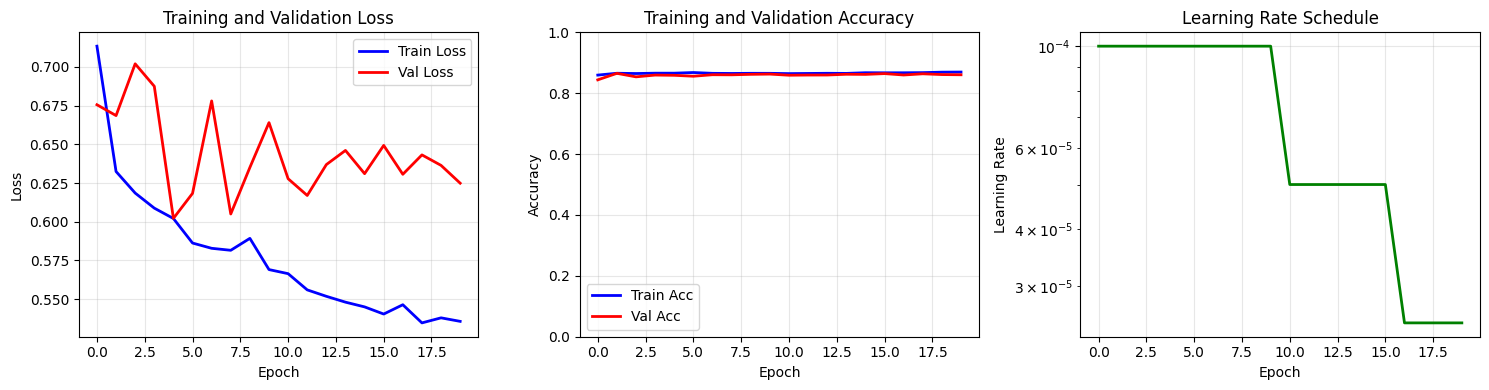

Training curves saved to transformer_outputs/training_curves.png


In [42]:
# ============================================================================
# PLOT TRAINING CURVES
# ============================================================================

fig, axes = plt.subplots(1, 3 if config.TASK != 'next_latent' else 2, figsize=(15, 4))

# Plot 1: Loss curves
ax1 = axes[0]
ax1.plot(history['train_loss'], label='Train Loss', color='blue', linewidth=2)
ax1.plot(history['val_loss'], label='Val Loss', color='red', linewidth=2)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Accuracy curves (if classification)
if config.TASK != 'next_latent':
    ax2 = axes[1]
    ax2.plot(history['train_acc'], label='Train Acc', color='blue', linewidth=2)
    ax2.plot(history['val_acc'], label='Val Acc', color='red', linewidth=2)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Training and Validation Accuracy')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim([0, 1])
    
    # Plot 3: Learning rate
    ax3 = axes[2]
else:
    ax3 = axes[1]

ax3.plot(history['lr'], color='green', linewidth=2)
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Learning Rate')
ax3.set_title('Learning Rate Schedule')
ax3.set_yscale('log')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUT_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"Training curves saved to {config.OUTPUT_DIR}/training_curves.png")

## Part 10: Model Evaluation

Comprehensive evaluation on the test set with detailed metrics.

In [44]:
# ============================================================================
# EVALUATION ON TEST SET
# ============================================================================

def evaluate_model(model, test_loader, device, task):
    """Comprehensive model evaluation."""
    model.eval()
    
    all_preds = []
    all_targets = []
    all_probs = []
    
    with torch.no_grad():
        for sequences, targets in test_loader:
            sequences = sequences.to(device)
            outputs = model(sequences)
            
            if task != 'next_latent':
                probs = F.softmax(outputs, dim=1)
                preds = outputs.argmax(dim=1)
                
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(targets.numpy())
                all_probs.extend(probs.cpu().numpy())
            else:
                all_preds.extend(outputs.cpu().numpy())
                all_targets.extend(targets.numpy())
    
    return np.array(all_preds), np.array(all_targets), np.array(all_probs) if all_probs else None

# Run evaluation
print("Evaluating model on test set...")
test_preds, test_targets, test_probs = evaluate_model(model, test_loader, device, config.TASK)

if config.TASK != 'next_latent':
    # Classification metrics
    print("\n" + "=" * 70)
    print("TEST SET EVALUATION RESULTS")
    print("=" * 70)
    
    # Basic metrics
    accuracy = accuracy_score(test_targets, test_preds)
    
    if config.TASK in ['ckc_classification', 'next_step_prediction']:
        # Multi-class metrics (8 classes: 0=normal, 1-7=malicious)
        precision = precision_score(test_targets, test_preds, average='weighted', zero_division=0)
        recall = recall_score(test_targets, test_preds, average='weighted', zero_division=0)
        f1 = f1_score(test_targets, test_preds, average='weighted', zero_division=0)
        
        # Per-class metrics
        precision_per_class = precision_score(test_targets, test_preds, average=None, zero_division=0)
        recall_per_class = recall_score(test_targets, test_preds, average=None, zero_division=0)
        
    else:  # early_warning (binary)
        precision = precision_score(test_targets, test_preds, zero_division=0)
        recall = recall_score(test_targets, test_preds, zero_division=0)
        f1 = f1_score(test_targets, test_preds, zero_division=0)
    
    print(f"\nOverall Metrics:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    
    # ROC-AUC (if binary or multi-class with probabilities)
    try:
        if config.TASK == 'early_warning':
            roc_auc = roc_auc_score(test_targets, test_probs[:, 1])
        else:
            roc_auc = roc_auc_score(test_targets, test_probs, multi_class='ovr')
        print(f"  ROC-AUC:   {roc_auc:.4f}")
    except Exception as e:
        print(f"  ROC-AUC:   Could not compute ({e})")
    
    # Classification report
    print("\n" + "-" * 70)
    print("Classification Report:")
    print("-" * 70)
    
    if config.TASK in ['ckc_classification', 'next_step_prediction']:
        target_names = [f"S{i}: {get_ckc_name(i)}" for i in range(config.NUM_CKC_CLASSES)]
    else:
        target_names = ['Safe', 'Dangerous']
    
    # Only use target names for classes that exist in the data
    unique_classes = np.unique(np.concatenate([test_targets, test_preds]))
    filtered_names = [target_names[i] for i in unique_classes if i < len(target_names)]
    
    print(classification_report(test_targets, test_preds, target_names=filtered_names, zero_division=0))

else:
    # Regression metrics for next_latent task
    print("\n" + "=" * 70)
    print("TEST SET EVALUATION RESULTS (Regression)")
    print("=" * 70)
    
    mse = mean_squared_error(test_targets, test_preds)
    mae = mean_absolute_error(test_targets, test_preds)
    rmse = np.sqrt(mse)
    
    print(f"\nRegression Metrics:")
    print(f"  MSE:  {mse:.6f}")
    print(f"  RMSE: {rmse:.6f}")
    print(f"  MAE:  {mae:.6f}")

Evaluating model on test set...

TEST SET EVALUATION RESULTS

Overall Metrics:
  Accuracy:  0.8669
  Precision: 0.9264
  Recall:    0.8669
  F1-Score:  0.8907
  ROC-AUC:   Could not compute (Number of classes in y_true not equal to the number of columns in 'y_score')

----------------------------------------------------------------------
Classification Report:
----------------------------------------------------------------------
                          precision    recall  f1-score   support

              S0: Benign       0.99      0.88      0.93     13738
      S1: Reconnaissance       0.08      0.69      0.14        94
            S3: Delivery       0.80      0.86      0.83      2423
        S4: Exploitation       0.45      0.65      0.53       646
        S5: Installation       0.65      0.85      0.74       190
S7: Actions on Objective       0.41      0.82      0.55       266

                accuracy                           0.87     17357
               macro avg       0.56 

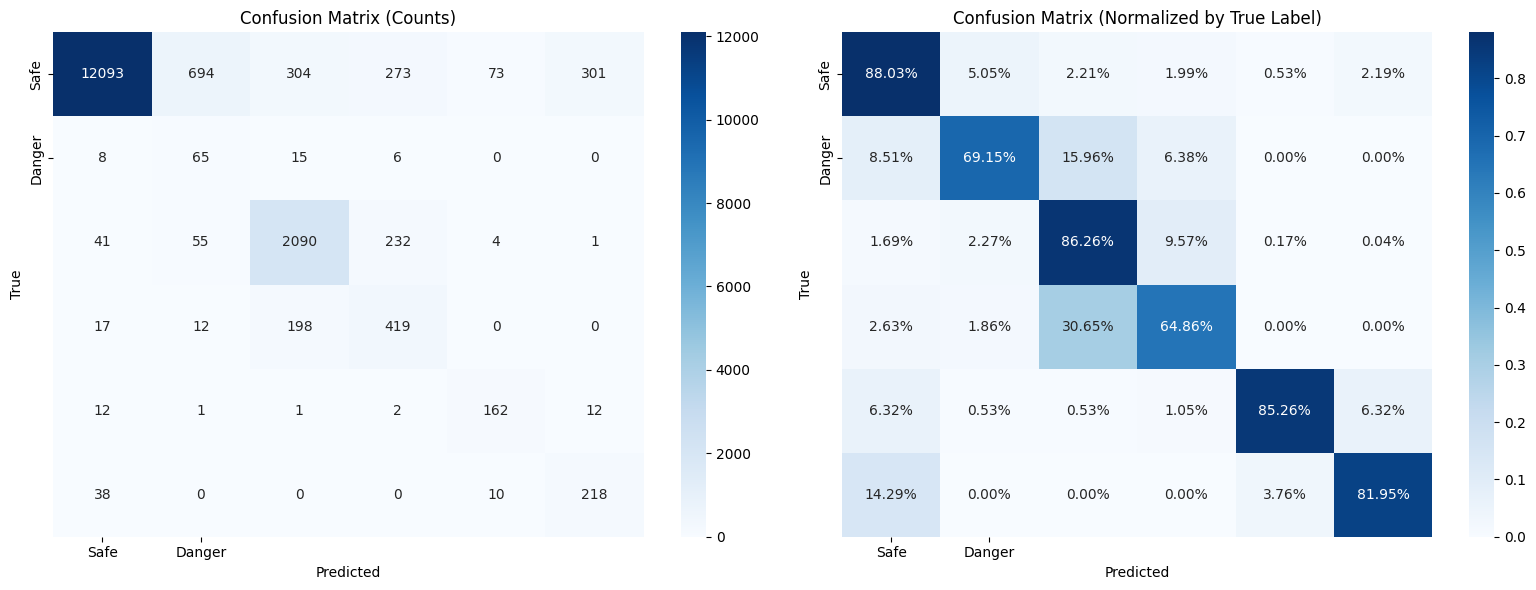


Confusion matrix saved to transformer_outputs/confusion_matrix.png


In [45]:
# ============================================================================
# CONFUSION MATRIX VISUALIZATION
# ============================================================================

if config.TASK != 'next_latent':
    # Compute confusion matrix
    cm = confusion_matrix(test_targets, test_preds)
    
    # Normalize by row (true labels)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)  # Handle division by zero
    
    # Create figure
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Plot 1: Raw counts
    if config.TASK == 'ckc_classification':
        labels = [f"S{i}" for i in range(config.NUM_CKC_CLASSES)]
    else:
        labels = ['Safe', 'Danger']
    
    # Filter labels to only those present in data
    unique_classes = np.unique(np.concatenate([test_targets, test_preds]))
    filtered_labels = [labels[i] for i in unique_classes if i < len(labels)]
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=filtered_labels, yticklabels=filtered_labels)
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_title('Confusion Matrix (Counts)')
    
    # Plot 2: Normalized
    sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues', ax=axes[1],
                xticklabels=filtered_labels, yticklabels=filtered_labels)
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    axes[1].set_title('Confusion Matrix (Normalized by True Label)')
    
    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\nConfusion matrix saved to {config.OUTPUT_DIR}/confusion_matrix.png")
    
    # Print per-class analysis
    if config.TASK == 'ckc_classification':
        print("\nPer-Class Analysis:")
        print("-" * 50)
        for i in unique_classes:
            if i < len(labels):
                true_count = np.sum(test_targets == i)
                pred_count = np.sum(test_preds == i)
                correct = cm[i, i] if i < cm.shape[0] else 0
                acc = correct / true_count if true_count > 0 else 0
                print(f"  {labels[i]} ({get_ckc_name(i)}): "
                      f"True={true_count:5d}, Pred={pred_count:5d}, Acc={acc:.2%}")

## Part 11: Early Warning Analysis (CKC Stage Progression)

Analyze the model's ability to detect attacks at early stages before they reach critical phases (S6, S7).

In [46]:
# ============================================================================
# EARLY WARNING ANALYSIS
# ============================================================================

if config.TASK == 'ckc_classification':
    print("=" * 70)
    print("EARLY WARNING ANALYSIS")
    print("=" * 70)
    print("\nGoal: Detect APT attacks BEFORE they reach critical stages (S6: C2, S7: Actions)")
    
    # Define stage groups
    early_stages = [1, 2, 3]      # Reconnaissance, Weaponization, Delivery
    middle_stages = [4, 5]         # Exploitation, Installation  
    critical_stages = [6, 7]       # C2, Actions on Objective
    
    # Analyze detection at each stage
    print("\n" + "-" * 70)
    print("Detection Rate by Attack Phase:")
    print("-" * 70)
    
    for stage_group, name in [(early_stages, "Early (S1-S3)"), 
                               (middle_stages, "Middle (S4-S5)"),
                               (critical_stages, "Critical (S6-S7)")]:
        mask = np.isin(test_targets, stage_group)
        if np.sum(mask) > 0:
            # Count as "detected" if predicted as any malicious stage (not benign)
            detected = np.sum(test_preds[mask] > 0)
            total = np.sum(mask)
            detection_rate = detected / total
            
            # Correctly classified within the exact stage
            exact_match = np.sum(test_preds[mask] == test_targets[mask])
            exact_rate = exact_match / total
            
            print(f"  {name}: Detection Rate = {detection_rate:.2%} | "
                  f"Exact Stage = {exact_rate:.2%} | "
                  f"({detected}/{total} detected, {exact_match}/{total} exact)")
    
    # False alarm rate (benign classified as malicious)
    benign_mask = test_targets == 0
    if np.sum(benign_mask) > 0:
        false_alarms = np.sum(test_preds[benign_mask] > 0)
        false_alarm_rate = false_alarms / np.sum(benign_mask)
        print(f"\n  False Alarm Rate (Benign → Malicious): {false_alarm_rate:.2%} "
              f"({false_alarms}/{np.sum(benign_mask)})")
    
    # Average detection lag (how many stages late)
    print("\n" + "-" * 70)
    print("Stage Prediction Accuracy (Confusion between adjacent stages):")
    print("-" * 70)
    
    malicious_mask = test_targets > 0
    if np.sum(malicious_mask) > 0:
        stage_diff = test_preds[malicious_mask] - test_targets[malicious_mask]
        avg_diff = np.mean(stage_diff)
        
        # Count off-by-one predictions
        off_by_one = np.sum(np.abs(stage_diff) == 1)
        off_by_more = np.sum(np.abs(stage_diff) > 1)
        exact = np.sum(stage_diff == 0)
        
        total_malicious = np.sum(malicious_mask)
        print(f"  Exact stage match: {exact}/{total_malicious} ({exact/total_malicious:.2%})")
        print(f"  Off by 1 stage:    {off_by_one}/{total_malicious} ({off_by_one/total_malicious:.2%})")
        print(f"  Off by >1 stages:  {off_by_more}/{total_malicious} ({off_by_more/total_malicious:.2%})")
        print(f"  Average stage difference: {avg_diff:+.2f}")

## Part 12: Attention Visualization

Visualize attention patterns to understand what the model focuses on in sequences.

Visualizing attention patterns...


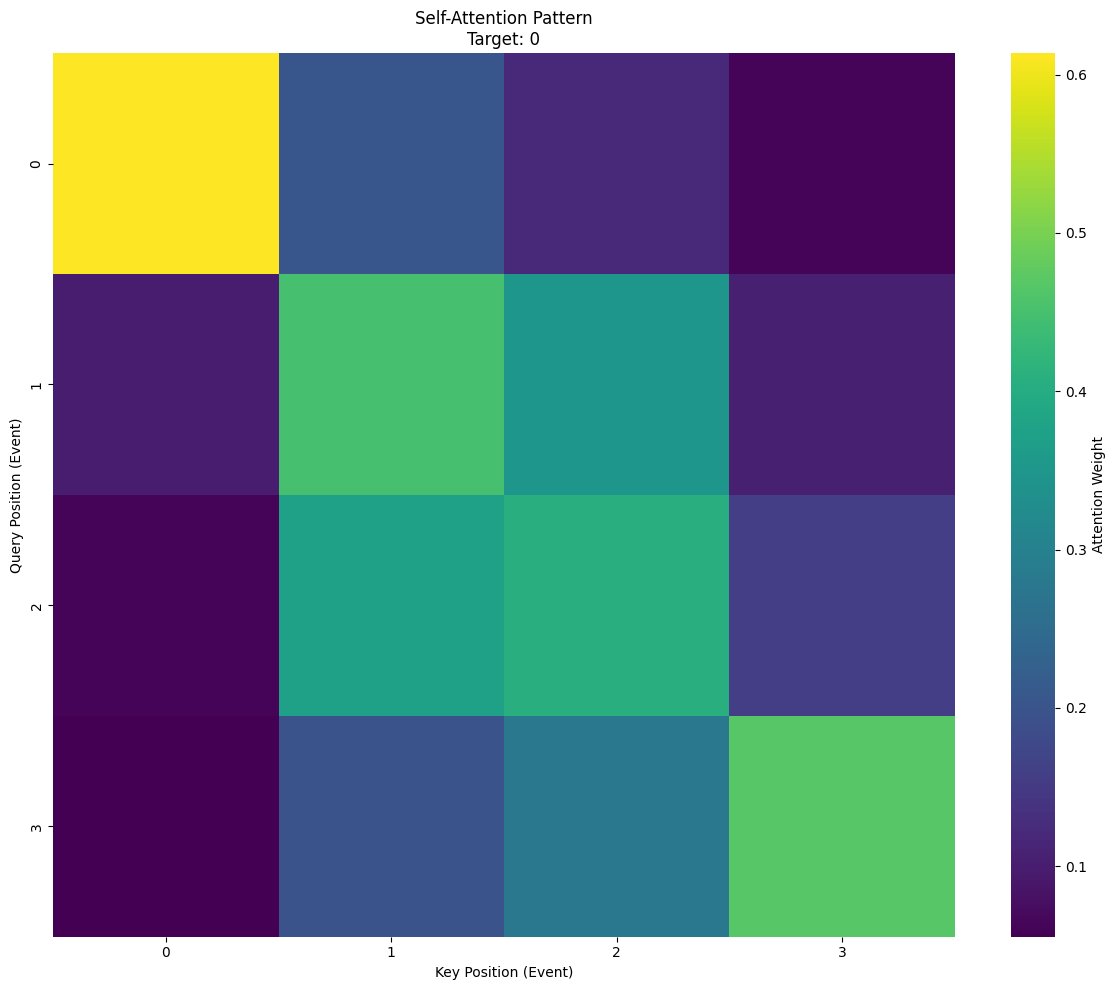

Attention visualization saved to transformer_outputs/attention_pattern.png


In [47]:
# ============================================================================
# ATTENTION VISUALIZATION
# ============================================================================

def visualize_attention(model, sample_sequence, device):
    """
    Visualize attention weights for a sample sequence.
    """
    model.eval()
    
    # Get attention weights using hooks
    attention_weights = []
    hooks = []
    
    def hook_fn(module, input, output):
        # MultiheadAttention returns (output, weights) when need_weights=True
        # But in the encoder, we need to access it differently
        pass
    
    # For visualization, we'll create a simple attention map
    # by computing self-attention manually for the first layer
    
    with torch.no_grad():
        x = sample_sequence.unsqueeze(0).to(device)  # (1, seq_len, input_dim)
        
        # Pass through input projection
        x_proj = model.input_projection(x)
        x_pos = model.pos_encoder(x_proj)
        
        # Get Q, K, V for visualization (simplified - first layer only)
        # This is an approximation since we can't easily extract attention from TransformerEncoder
        
        # Compute attention scores manually using the projected input
        d_k = model.d_model
        scores = torch.matmul(x_pos, x_pos.transpose(-2, -1)) / np.sqrt(d_k)
        attention = F.softmax(scores, dim=-1)
    
    return attention[0].cpu().numpy()

# Visualize attention for a sample
print("Visualizing attention patterns...")

# Get a sample sequence from test set
sample_idx = 0
for seq, target in test_loader:
    sample_seq = seq[sample_idx]
    sample_target = target[sample_idx].item()
    break

attention_map = visualize_attention(model, sample_seq, device)

# Plot attention heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(attention_map, cmap='viridis', cbar_kws={'label': 'Attention Weight'})
plt.xlabel('Key Position (Event)')
plt.ylabel('Query Position (Event)')
plt.title(f'Self-Attention Pattern\nTarget: {get_ckc_name(sample_target) if config.TASK == "ckc_classification" else sample_target}')

plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUT_DIR, 'attention_pattern.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"Attention visualization saved to {config.OUTPUT_DIR}/attention_pattern.png")

## Part 13: Save Model and Results

Save the trained model and all evaluation results.

In [48]:
# ============================================================================
# SAVE MODEL AND RESULTS
# ============================================================================

print("=" * 70)
print("SAVING MODEL AND RESULTS")
print("=" * 70)

# 1. Save model weights
model_path = os.path.join(config.OUTPUT_DIR, f'transformer_{config.TASK}.pth')
torch.save({
    'model_state_dict': model.state_dict(),
    'config': {
        'input_dim': config.INPUT_DIM,
        'd_model': config.D_MODEL,
        'n_heads': config.N_HEADS,
        'n_encoder_layers': config.N_ENCODER_LAYERS,
        'dim_feedforward': config.DIM_FEEDFORWARD,
        'dropout': config.DROPOUT,
        'task': config.TASK,
        'num_classes': num_classes,
        'positional_encoding': config.POSITIONAL_ENCODING,
        'max_seq_length': config.MAX_SEQ_LENGTH,
        'seq_length': config.SEQ_LENGTH
    }
}, model_path)
print(f"✓ Model saved to: {model_path}")

# 2. Save training history
history_df = pd.DataFrame(history)
history_path = os.path.join(config.OUTPUT_DIR, 'training_history.csv')
history_df.to_csv(history_path, index=False)
print(f"✓ Training history saved to: {history_path}")

# 3. Save evaluation results
if config.TASK != 'next_latent':
    results = {
        'task': config.TASK,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'num_train': len(train_dataset),
        'num_val': len(val_dataset),
        'num_test': len(test_dataset),
        'epochs_trained': len(history['train_loss']),
        'best_val_loss': -early_stopping.best_score if early_stopping.best_score else None
    }
    
    # Add ROC-AUC if computed
    try:
        results['roc_auc'] = roc_auc
    except:
        pass
else:
    results = {
        'task': config.TASK,
        'mse': mse,
        'rmse': rmse,
        'mae': mae,
        'num_train': len(train_dataset),
        'num_val': len(val_dataset),
        'num_test': len(test_dataset),
        'epochs_trained': len(history['train_loss']),
        'best_val_loss': -early_stopping.best_score if early_stopping.best_score else None
    }

results_path = os.path.join(config.OUTPUT_DIR, 'evaluation_results.json')
import json
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2)
print(f"✓ Evaluation results saved to: {results_path}")

# 4. Save predictions
predictions_path = os.path.join(config.OUTPUT_DIR, 'test_predictions.npz')
np.savez(predictions_path, 
         predictions=test_preds, 
         targets=test_targets,
         probabilities=test_probs if test_probs is not None else np.array([]))
print(f"✓ Predictions saved to: {predictions_path}")

# 5. Save configuration
config_dict = {k: v for k, v in vars(TransformerConfig).items() 
               if not k.startswith('_') and not callable(v)}
config_path = os.path.join(config.OUTPUT_DIR, 'config.json')
with open(config_path, 'w') as f:
    json.dump(config_dict, f, indent=2, default=str)
print(f"✓ Configuration saved to: {config_path}")

print("\n" + "=" * 70)
print("ALL OUTPUTS SAVED SUCCESSFULLY!")
print("=" * 70)

SAVING MODEL AND RESULTS
✓ Model saved to: transformer_outputs\transformer_next_step_prediction.pth
✓ Training history saved to: transformer_outputs\training_history.csv
✓ Evaluation results saved to: transformer_outputs\evaluation_results.json
✓ Predictions saved to: transformer_outputs\test_predictions.npz
✓ Configuration saved to: transformer_outputs\config.json

ALL OUTPUTS SAVED SUCCESSFULLY!


## Part 14: Inference Function for New Sequences

Create a reusable function for making predictions on new data.

In [50]:
# ============================================================================
# INFERENCE FUNCTION FOR NEW SEQUENCES
# ============================================================================

class CKCPredictor:
    """
    Inference class for making predictions on new SIEM event sequences.
    
    Usage:
        predictor = CKCPredictor(model_path, device)
        stage, probabilities = predictor.predict(latent_sequence)
    """
    
    def __init__(self, model_path: str, device: torch.device = None):
        """
        Load trained model for inference.
        
        Args:
            model_path: Path to saved model checkpoint
            device: Device to run inference on
        """
        self.device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        
        # Load checkpoint
        checkpoint = torch.load(model_path, map_location=self.device)
        model_config = checkpoint['config']
        
        # Extract seq_length before creating model (it's not a model parameter)
        self.seq_length = model_config.pop('seq_length', 4)
        
        # Recreate model
        self.model = CKCTransformer(**model_config).to(self.device)
        self.model.load_state_dict(checkpoint['model_state_dict'])
        self.model.eval()
        
        self.task = model_config['task']
        
        print(f"Model loaded for task: {self.task}")
        print(f"Expected sequence length: {self.seq_length}")
    
    def predict(
        self, 
        latent_sequence: np.ndarray,
        return_probabilities: bool = True
    ) -> Tuple[Union[int, np.ndarray], Optional[np.ndarray]]:
        """
        Make prediction on a sequence of latent vectors.
        
        Args:
            latent_sequence: (seq_len, latent_dim) array of latent vectors
            return_probabilities: Whether to return class probabilities
        
        Returns:
            prediction: Predicted class (or vector for regression)
            probabilities: Class probabilities (None for regression)
        """
        # Ensure correct shape
        if len(latent_sequence.shape) == 1:
            latent_sequence = latent_sequence.reshape(1, -1)
        
        # Pad or truncate to expected length
        if latent_sequence.shape[0] < self.seq_length:
            # Pad with zeros at the beginning
            padding = np.zeros((self.seq_length - latent_sequence.shape[0], 
                               latent_sequence.shape[1]))
            latent_sequence = np.vstack([padding, latent_sequence])
        elif latent_sequence.shape[0] > self.seq_length:
            # Take the last seq_length events
            latent_sequence = latent_sequence[-self.seq_length:]
        
        # Convert to tensor
        x = torch.FloatTensor(latent_sequence).unsqueeze(0).to(self.device)
        
        with torch.no_grad():
            output = self.model(x)
            
            if self.task == 'next_latent':
                return output.cpu().numpy()[0], None
            else:
                probs = F.softmax(output, dim=1).cpu().numpy()[0]
                pred = output.argmax(dim=1).item()
                
                if return_probabilities:
                    return pred, probs
                return pred, None
    
    def predict_batch(
        self, 
        sequences: np.ndarray
    ) -> Tuple[np.ndarray, Optional[np.ndarray]]:
        """
        Make predictions on a batch of sequences.
        
        Args:
            sequences: (batch, seq_len, latent_dim) array
        
        Returns:
            predictions: Array of predictions
            probabilities: Array of class probabilities
        """
        x = torch.FloatTensor(sequences).to(self.device)
        
        with torch.no_grad():
            outputs = self.model(x)
            
            if self.task == 'next_latent':
                return outputs.cpu().numpy(), None
            else:
                probs = F.softmax(outputs, dim=1).cpu().numpy()
                preds = outputs.argmax(dim=1).cpu().numpy()
                return preds, probs
    
    def get_ckc_stage_name(self, stage: int) -> str:
        """Get human-readable CKC stage name."""
        return get_ckc_name(stage)

# Create predictor instance
predictor = CKCPredictor(model_path, device)

# Example usage
print("\n" + "-" * 70)
print("Example Inference:")
print("-" * 70)

# Get a test sample
for seq, target in test_loader:
    sample = seq[0].numpy()
    true_label = target[0].item()
    break

pred, probs = predictor.predict(sample)

print(f"True label: {true_label} ({get_ckc_name(true_label)})")
print(f"Predicted:  {pred} ({get_ckc_name(pred)})")
if probs is not None:
    print(f"\nClass probabilities:")
    for i, p in enumerate(probs):
        if p > 0.01:  # Only show significant probabilities
            print(f"  {get_ckc_name(i)}: {p:.2%}")

Model loaded for task: next_step_prediction
Expected sequence length: 4

----------------------------------------------------------------------
Example Inference:
----------------------------------------------------------------------
True label: 0 (Benign)
Predicted:  0 (Benign)

Class probabilities:
  Benign: 99.47%


## Part 15: Summary and Next Steps

Final summary of the Transformer model for APT detection.

In [51]:
# ============================================================================
# FINAL SUMMARY
# ============================================================================

print("=" * 70)
print("TRANSFORMER MODEL FOR APT ATTACK DETECTION - SUMMARY")
print("=" * 70)

print("\n📊 MODEL ARCHITECTURE:")
print(f"   • Input: Sequences of {config.INPUT_DIM}-dim latent vectors")
print(f"   • Transformer: d_model={config.D_MODEL}, {config.N_HEADS} heads, {config.N_ENCODER_LAYERS} layers")
print(f"   • Parameters: {count_parameters(model):,}")
print(f"   • Task: {config.TASK}")

print("\n📈 TRAINING:")
print(f"   • Epochs trained: {len(history['train_loss'])}")
print(f"   • Training samples: {len(train_dataset):,}")
print(f"   • Best validation loss: {-early_stopping.best_score:.4f}")

print("\n🎯 PERFORMANCE:")
if config.TASK != 'next_latent':
    print(f"   • Accuracy:  {accuracy:.4f}")
    print(f"   • Precision: {precision:.4f}")
    print(f"   • Recall:    {recall:.4f}")
    print(f"   • F1-Score:  {f1:.4f}")
    try:
        print(f"   • ROC-AUC:   {roc_auc:.4f}")
    except:
        pass
else:
    print(f"   • MSE:  {mse:.6f}")
    print(f"   • RMSE: {rmse:.6f}")
    print(f"   • MAE:  {mae:.6f}")

print("\n💾 SAVED FILES:")
print(f"   • Model: {model_path}")
print(f"   • History: {history_path}")
print(f"   • Results: {results_path}")
print(f"   • Config: {config_path}")

print("\n🚀 NEXT STEPS:")
print("   1. Try different tasks: 'early_warning' or 'next_latent'")
print("   2. Experiment with hyperparameters (d_model, n_heads, n_layers)")
print("   3. Adjust sequence length based on typical attack duration")
print("   4. Use ensemble with autoencoder anomaly scores")
print("   5. Deploy for real-time SIEM monitoring")

print("\n" + "=" * 70)
print("Notebook complete! 🎉")
print("=" * 70)

TRANSFORMER MODEL FOR APT ATTACK DETECTION - SUMMARY

📊 MODEL ARCHITECTURE:
   • Input: Sequences of 64-dim latent vectors
   • Transformer: d_model=128, 8 heads, 4 layers
   • Parameters: 810,696
   • Task: next_step_prediction

📈 TRAINING:
   • Epochs trained: 20
   • Training samples: 80,994
   • Best validation loss: 0.6022

🎯 PERFORMANCE:
   • Accuracy:  0.8669
   • Precision: 0.9264
   • Recall:    0.8669
   • F1-Score:  0.8907

💾 SAVED FILES:
   • Model: transformer_outputs\transformer_next_step_prediction.pth
   • History: transformer_outputs\training_history.csv
   • Results: transformer_outputs\evaluation_results.json
   • Config: transformer_outputs\config.json

🚀 NEXT STEPS:
   1. Try different tasks: 'early_warning' or 'next_latent'
   2. Experiment with hyperparameters (d_model, n_heads, n_layers)
   3. Adjust sequence length based on typical attack duration
   4. Use ensemble with autoencoder anomaly scores
   5. Deploy for real-time SIEM monitoring

Notebook complete! 🎉

## Part 16: Test Scenario - 30 Sequence Predictions

Let's test the Transformer with 30 real sequences (mix of benign and malicious) and compare predictions with actual labels.

In [52]:
# ============================================================================
# TEST SCENARIO: 30 SEQUENCES - BENIGN AND MALICIOUS
# ============================================================================

print("=" * 90)
print("🧪 TEST SCENARIO: 30 SEQUENCE PREDICTIONS")
print("=" * 90)
print("\nTask: Given 4 events, predict what the NEXT (5th) event will be")
print("      - Class 0: Normal/Benign traffic")
print("      - Class 1-7: Malicious CKC attack stages\n")

# Get test samples - select a mix of benign and malicious
model.eval()

# Find indices for different classes in test set
benign_indices = np.where(test_targets == 0)[0]
malicious_indices = np.where(test_targets > 0)[0]

# Select 15 benign and 15 malicious (or as many as available)
np.random.seed(42)
n_benign = min(15, len(benign_indices))
n_malicious = min(15, len(malicious_indices))

selected_benign = np.random.choice(benign_indices, n_benign, replace=False)
selected_malicious = np.random.choice(malicious_indices, n_malicious, replace=False)

# Combine and shuffle
selected_indices = np.concatenate([selected_benign, selected_malicious])
np.random.shuffle(selected_indices)

print(f"📊 Selected {len(selected_indices)} test sequences:")
print(f"   - {n_benign} sequences where next event is BENIGN")
print(f"   - {n_malicious} sequences where next event is MALICIOUS")

# Prepare results table
print("\n" + "=" * 90)
print(f"{'#':<3} {'Input Sequence (4 events)':<40} {'True Next':<25} {'Predicted':<25} {'Match':<6}")
print("=" * 90)

results_list = []
correct_count = 0
correct_benign = 0
correct_malicious = 0

for i, idx in enumerate(selected_indices):
    # Get the sequence and target
    seq_data = full_dataset.sequences[test_dataset.indices[idx]]
    seq_indices, next_idx = seq_data
    
    # Get the CKC labels of the input sequence
    input_labels = [ckc_labels[j] for j in seq_indices]
    input_stages = [f"S{l}" for l in input_labels]
    
    # True next label
    true_label = ckc_labels[next_idx]
    true_name = get_ckc_name(true_label)
    
    # Get prediction
    sequence = latent_vectors[seq_indices]
    pred, probs = predictor.predict(sequence)
    pred_name = get_ckc_name(pred)
    
    # Check if correct
    is_correct = pred == true_label
    if is_correct:
        correct_count += 1
        if true_label == 0:
            correct_benign += 1
        else:
            correct_malicious += 1
    
    match_symbol = "✅" if is_correct else "❌"
    
    # Format output
    input_str = " → ".join(input_stages)
    true_str = f"S{true_label}: {true_name[:15]}"
    pred_str = f"S{pred}: {pred_name[:15]}"
    
    print(f"{i+1:<3} {input_str:<40} {true_str:<25} {pred_str:<25} {match_symbol:<6}")
    
    results_list.append({
        'sequence_num': i+1,
        'input_sequence': input_str,
        'true_label': true_label,
        'true_name': true_name,
        'predicted_label': pred,
        'predicted_name': pred_name,
        'correct': is_correct,
        'confidence': probs[pred] if probs is not None else None
    })

# Summary
print("=" * 90)
print(f"\n📈 RESULTS SUMMARY:")
print(f"   Total Correct: {correct_count}/{len(selected_indices)} ({100*correct_count/len(selected_indices):.1f}%)")
print(f"   Benign Correct: {correct_benign}/{n_benign} ({100*correct_benign/n_benign:.1f}%)")
print(f"   Malicious Correct: {correct_malicious}/{n_malicious} ({100*correct_malicious/n_malicious:.1f}%)")

# Create a DataFrame for better visualization
results_df = pd.DataFrame(results_list)
print("\n" + "-" * 90)

🧪 TEST SCENARIO: 30 SEQUENCE PREDICTIONS

Task: Given 4 events, predict what the NEXT (5th) event will be
      - Class 0: Normal/Benign traffic
      - Class 1-7: Malicious CKC attack stages

📊 Selected 30 test sequences:
   - 15 sequences where next event is BENIGN
   - 15 sequences where next event is MALICIOUS

#   Input Sequence (4 events)                True Next                 Predicted                 Match 
1   S0 → S4 → S0 → S4                        S4: Exploitation          S4: Exploitation          ✅     
2   S5 → S0 → S5 → S5                        S5: Installation          S5: Installation          ✅     
3   S0 → S0 → S0 → S0                        S0: Benign                S0: Benign                ✅     
4   S0 → S0 → S3 → S0                        S0: Benign                S3: Delivery              ❌     
5   S0 → S0 → S1 → S0                        S0: Benign                S0: Benign                ✅     
6   S3 → S3 → S3 → S3                        S3: Delivery  


🔍 DETAILED ANALYSIS WITH CONFIDENCE SCORES

📌 CORRECTLY PREDICTED MALICIOUS SEQUENCES:
------------------------------------------------------------------------------------------
  Sequence #1: S0 → S4 → S0 → S4
    → Next event: Exploitation (Confidence: 93.4%)

  Sequence #2: S5 → S0 → S5 → S5
    → Next event: Installation (Confidence: 99.6%)

  Sequence #6: S3 → S3 → S3 → S3
    → Next event: Delivery (Confidence: 74.6%)

  Sequence #8: S3 → S3 → S3 → S3
    → Next event: Delivery (Confidence: 74.5%)

  Sequence #9: S3 → S3 → S3 → S3
    → Next event: Delivery (Confidence: 73.7%)


📌 CORRECTLY PREDICTED BENIGN SEQUENCES:
------------------------------------------------------------------------------------------
  Sequence #3: S0 → S0 → S0 → S0
    → Next event: Benign (Confidence: 99.9%)

  Sequence #5: S0 → S0 → S1 → S0
    → Next event: Benign (Confidence: 87.8%)

  Sequence #7: S0 → S0 → S0 → S0
    → Next event: Benign (Confidence: 99.5%)

  Sequence #11: S0 → S0 → S0 → S0
    →

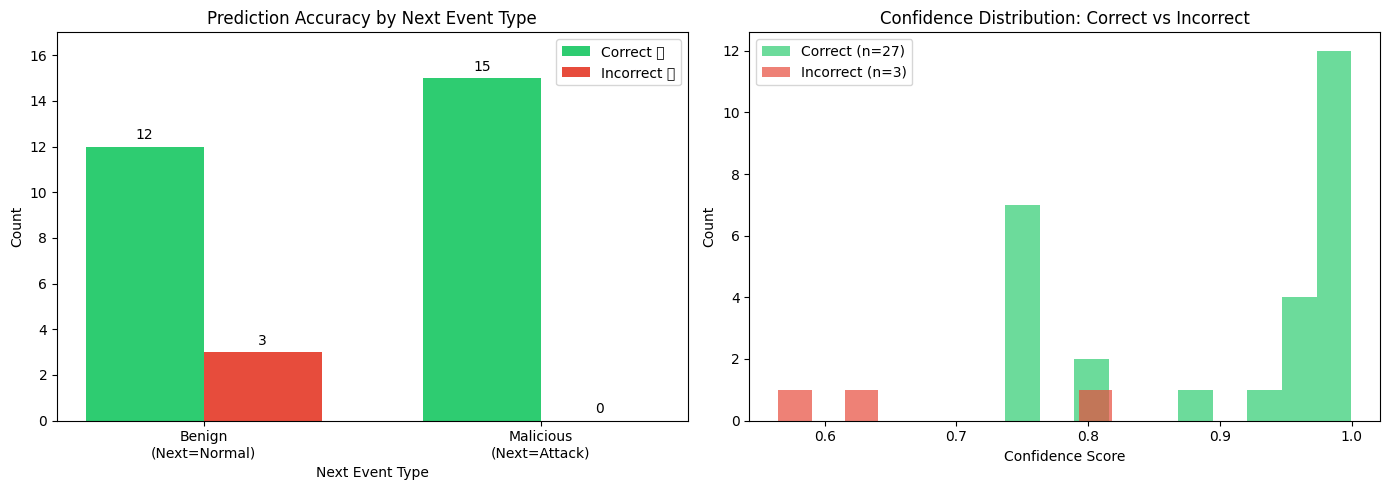


✅ Test scenario visualization saved to transformer_outputs/test_scenario_30_sequences.png


In [53]:
# ============================================================================
# DETAILED VIEW: Show confidence scores and analysis
# ============================================================================

print("\n" + "=" * 90)
print("🔍 DETAILED ANALYSIS WITH CONFIDENCE SCORES")
print("=" * 90)

# Show some interesting cases
print("\n📌 CORRECTLY PREDICTED MALICIOUS SEQUENCES:")
print("-" * 90)

correct_malicious_cases = [r for r in results_list if r['correct'] and r['true_label'] > 0]
for r in correct_malicious_cases[:5]:
    print(f"  Sequence #{r['sequence_num']}: {r['input_sequence']}")
    print(f"    → Next event: {r['true_name']} (Confidence: {r['confidence']*100:.1f}%)")
    print()

print("\n📌 CORRECTLY PREDICTED BENIGN SEQUENCES:")
print("-" * 90)

correct_benign_cases = [r for r in results_list if r['correct'] and r['true_label'] == 0]
for r in correct_benign_cases[:5]:
    print(f"  Sequence #{r['sequence_num']}: {r['input_sequence']}")
    print(f"    → Next event: {r['true_name']} (Confidence: {r['confidence']*100:.1f}%)")
    print()

print("\n📌 INCORRECT PREDICTIONS (Errors):")
print("-" * 90)

incorrect_cases = [r for r in results_list if not r['correct']]
for r in incorrect_cases[:10]:
    print(f"  Sequence #{r['sequence_num']}: {r['input_sequence']}")
    print(f"    → True: {r['true_name']} | Predicted: {r['predicted_name']} (Conf: {r['confidence']*100:.1f}%)")
    print()

# Visual summary
print("\n" + "=" * 90)
print("📊 VISUAL SUMMARY")
print("=" * 90)

# Create a simple visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Correct vs Incorrect by type
categories = ['Benign\n(Next=Normal)', 'Malicious\n(Next=Attack)']
correct_vals = [correct_benign, correct_malicious]
incorrect_vals = [n_benign - correct_benign, n_malicious - correct_malicious]

x = np.arange(len(categories))
width = 0.35

bars1 = axes[0].bar(x - width/2, correct_vals, width, label='Correct ✅', color='#2ecc71')
bars2 = axes[0].bar(x + width/2, incorrect_vals, width, label='Incorrect ❌', color='#e74c3c')

axes[0].set_xlabel('Next Event Type')
axes[0].set_ylabel('Count')
axes[0].set_title('Prediction Accuracy by Next Event Type')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories)
axes[0].legend()
axes[0].set_ylim(0, max(n_benign, n_malicious) + 2)

# Add count labels on bars
for bar in bars1:
    height = bar.get_height()
    axes[0].annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')
for bar in bars2:
    height = bar.get_height()
    axes[0].annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

# Plot 2: Confidence distribution
confidences = [r['confidence'] for r in results_list if r['confidence'] is not None]
correct_conf = [r['confidence'] for r in results_list if r['correct'] and r['confidence'] is not None]
incorrect_conf = [r['confidence'] for r in results_list if not r['correct'] and r['confidence'] is not None]

axes[1].hist(correct_conf, bins=10, alpha=0.7, label=f'Correct (n={len(correct_conf)})', color='#2ecc71')
axes[1].hist(incorrect_conf, bins=10, alpha=0.7, label=f'Incorrect (n={len(incorrect_conf)})', color='#e74c3c')
axes[1].set_xlabel('Confidence Score')
axes[1].set_ylabel('Count')
axes[1].set_title('Confidence Distribution: Correct vs Incorrect')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(config.OUTPUT_DIR, 'test_scenario_30_sequences.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Test scenario visualization saved to {config.OUTPUT_DIR}/test_scenario_30_sequences.png")